In [ ]:
%pip install matplotlib seaborn numpy pandas torch datasets transformers

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy
import gc

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
n_samples = 32

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


In [6]:
eval_ppl(model, testloader, device=DEV)

11.781546592712402

## Stored results

In [7]:
importance = pd.read_csv('results/importance.csv', index_col=0)

In [8]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.grad_imp = torch.Tensor(importance.iloc[:, i])

In [9]:
norms_L1 = pd.read_csv('results/large_files/norms_L1.csv', index_col=0)
norms_L2 = pd.read_csv('results/large_files/norms_L2.csv', index_col=0)
norms_max = pd.read_csv('results/large_files/norms_max.csv', index_col=0)
norm_L2_means = norms_L2.mean()

rel_norms_L1 = pd.read_csv('results/large_files/rel_norms_L1.csv', index_col=0)
rel_norms_L2 = pd.read_csv('results/large_files/rel_norms_L2.csv', index_col=0)
rel_norms_max = pd.read_csv('results/large_files/rel_norms_max.csv', index_col=0)

w_rel_norms_L1 = pd.read_csv('results/large_files/w_rel_norms_L1.csv', index_col=0)
w_rel_norms_L2 = pd.read_csv('results/large_files/w_rel_norms_L2.csv', index_col=0)
w_rel_norms_max = pd.read_csv('results/large_files/w_rel_norms_max.csv', index_col=0)

In [10]:
for i, layer in enumerate(model.model.layers):
    # calculate average norm for each mlp
    mlp = layer.mlp

    mlp.norms_L1 = torch.tensor(norms_L1.iloc[:, i])
    mlp.norms_L2 = torch.tensor(norms_L2.iloc[:, i])
    mlp.norms_max = torch.tensor(norms_max.iloc[:, i])

    mlp.rel_norms_L1 = torch.tensor(rel_norms_L1.iloc[:, i])
    mlp.rel_norms_L2 = torch.tensor(rel_norms_L2.iloc[:, i])
    mlp.rel_norms_max = torch.tensor(rel_norms_max.iloc[:, i])

In [11]:
results = pd.read_csv('results/results.csv', index_col=0)
results2 = pd.read_csv('results/results2.csv', index_col=0)
results_deep = pd.read_csv('results/results_deep.csv', index_col=0)
results_deep2 = pd.read_csv('results/results_deep2.csv', index_col=0)
results_1_layer = pd.read_csv('results/results_1_layer.csv', index_col=0)
results_rand = pd.read_csv('results/results_rand.csv', index_col=0)
results_overall_imp = pd.read_csv('results/results_overall_imp.csv', index_col=0)
results_w_rel_L2 = pd.read_csv('results/results_w_rel_L2.csv', index_col=0)

results_threshold = pd.read_csv('results/results_threshold.csv', header=[0, 1], index_col=0)
results_thr_keeping_layers = pd.read_csv('results/results_thr_keeping_layers.csv', index_col=0)
results_threshold_except = pd.read_csv('results/results_threshold_except.csv', header=[0, 1], index_col=0)
results_threshold_rel_except = pd.read_csv('results/results_threshold_rel_except.csv', header=[0, 1], index_col=0)
results_threshold_w_rel_except = pd.read_csv('results/results_threshold_w_rel_except.csv', header=[0, 1], index_col=0)

block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24

---
# Compute neuron importance based on gradients

In [8]:
model.gradient_checkpointing_enable()
model.config.use_cache = False
model.train()


def b_hook(module, _, grad_out):
    X = grad_out[0].detach().cpu().float()
    X = X.reshape(-1, X.shape[-1])
    # update neuron gradient importance
    module.grad_imp += X.square().mean(dim=0) * 1e6

for param in model.parameters():
    param.requires_grad = True

hooks = []
for layer in model.model.layers:
    mlp = layer.mlp
    mlp.grad_imp = torch.zeros(mlp.down_proj.out_features, device='cpu')
    h = mlp.register_full_backward_hook(b_hook)
    hooks.append(h)

for idx, (bx, _) in enumerate(dataloader):
    bx = bx.cuda()
    lm_logits = model(bx.cuda()).logits
    shift_logits = lm_logits[:, :-1, :].contiguous()
    shift_labels = bx[:, 1:]
    loss_fct = nn.CrossEntropyLoss()
    loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
    loss.backward()
    if idx > 7: break

model.config.use_cache = True
for h in hooks:
    h.remove()

In [12]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.thresholds_L1, mlp.thresholds_L2, mlp.thresholds_max = {}, {}, {}
    mlp.rel_thresholds_L1, mlp.rel_thresholds_L2, mlp.rel_thresholds_max = {}, {}, {}
    mlp.w_rel_thresholds_L1, mlp.w_rel_thresholds_L2, mlp.w_rel_thresholds_max = {}, {}, {}
    for q in range(10, 71, 5):
        q /= 100
        # set thresholds for each layer
        mlp.thresholds_L1[q] = norms_L1.iloc[:, i].quantile(q)
        mlp.thresholds_L2[q] = norms_L2.iloc[:, i].quantile(q)
        mlp.thresholds_max[q] = norms_max.iloc[:, i].quantile(q)

        mlp.rel_thresholds_L1[q] = rel_norms_L1.iloc[:, i].quantile(q)
        mlp.rel_thresholds_L2[q] = rel_norms_L2.iloc[:, i].quantile(q)
        mlp.rel_thresholds_max[q] = rel_norms_max.iloc[:, i].quantile(q)

        mlp.w_rel_thresholds_L1[q] = w_rel_norms_L1.iloc[:, i].quantile(q)
        mlp.w_rel_thresholds_L2[q] = w_rel_norms_L2.iloc[:, i].quantile(q)
        mlp.w_rel_thresholds_max[q] = w_rel_norms_max.iloc[:, i].quantile(q)

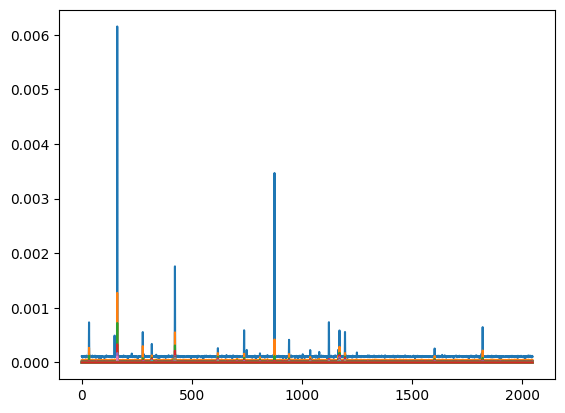

In [9]:
for layer in model.model.layers:
    plt.plot(layer.mlp.grad_imp.cpu())

In [10]:
# collect neuron importance from layers
importance = pd.DataFrame({
    i: layer.mlp.grad_imp.cpu()
    for i, layer in enumerate(model.model.layers)})

importance.to_csv('importance.csv')


---
# Compute MLP output norm


In [21]:
model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

In [20]:
@torch.no_grad()
def compute_mlp_norm(model):
    def hook_mlp(module, inps, outs):
        outs_abs = outs.abs()
        module.norms_L1.extend(
            outs_abs.sum(dim=2).cpu().flatten().tolist())
        module.norms_L2.extend(
            outs_abs.norm(dim=2).cpu().flatten().tolist())
        module.norms_max.extend(
            outs_abs.max(dim=2).values.cpu().flatten().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.norms_L1 = []
        layer.mlp.norms_L2 = []
        layer.mlp.norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_norm(model)

In [13]:
# collect norms from layers
norms_L1 = pd.DataFrame({
    i: layer.mlp.norms_L1
    for i, layer in enumerate(model.model.layers)})
norms_L2 = pd.DataFrame({
    i: layer.mlp.norms_L2
    for i, layer in enumerate(model.model.layers)})
norms_max = pd.DataFrame({
    i: layer.mlp.norms_max
    for i, layer in enumerate(model.model.layers)})

norm_L2_means = norms_L2.mean()

norms_L1.to_csv('norms_L1.csv')
norms_L2.to_csv('norms_L2.csv')
norms_max.to_csv('norms_max.csv')

[14.517113208770752, 18.388416409492493, 19.324568793177605, 25.971057772636414, 28.535166144371033, 31.641284108161926, 36.316221475601196, 52.295472621917725, 50.88528347015381, 57.39054161310196, 58.834558963775635, 61.97533345222473, 59.953614234924316, 66.3242199420929, 80.69355094432831, 92.67101660370827, 115.67223984003067, 144.47405041754246, 192.8752191066742, 232.75766277313232, 257.75736808776855, 306.33427810668945, 417.5819282531738, 1903.5644989013672]


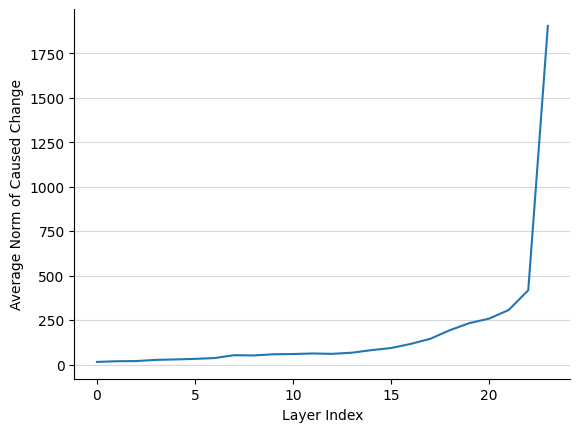

In [14]:
print(list(norm_L2_means))
plt.plot(norm_L2_means)
plt.xlabel('Layer Index')
plt.ylabel('Average Norm of Caused Change')
plt.grid(axis='y', alpha=0.5)
sns.despine()

## Norm distribution

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
axes = axes.flatten()

for i, column in enumerate(norms_L2.columns):
    ax = axes[i]
    ax.hist(norms_L2[column], bins=15, alpha=0.7, color='blue')
    ax.set_title(f'Layer {column}', fontsize=10)
    if i >= len(norms_L2.columns) - 6:
        ax.set_xlabel('Norm Value', fontsize=8)
    if i % 6 == 0:
        ax.set_ylabel('Frequency', fontsize=8)
    sns.despine()

plt.tight_layout()
plt.show()


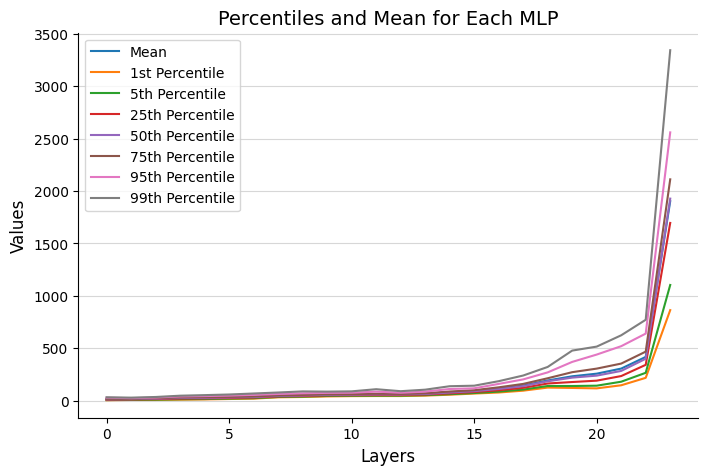

In [16]:
percentiles = [1, 5, 25, 50, 75, 95, 99]

summary = pd.DataFrame({
    "Mean": norms_L2.mean(),
    "1st Percentile": norms_L2.quantile(0.01),
    "5th Percentile": norms_L2.quantile(0.05),
    "25th Percentile": norms_L2.quantile(0.25),
    "50th Percentile": norms_L2.median(),
    "75th Percentile": norms_L2.quantile(0.75),
    "95th Percentile": norms_L2.quantile(0.95),
    "99th Percentile": norms_L2.quantile(0.99)
})

# Plot percentiles and mean for each column
plt.figure(figsize=(8, 5))
for column in summary.columns:
    plt.plot(summary.index, summary[column], label=column)

plt.title("Percentiles and Mean for Each MLP", fontsize=14)
plt.xlabel("Layers", fontsize=12)
plt.ylabel("Values", fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis='y', alpha=0.5)
sns.despine()
plt.show()

# Compute relative norm of MLP output


In [23]:
def rel_L1_norm(inps_abs, outs_abs):
    return outs_abs.sum(dim=2, keepdim=True) / inps_abs.sum(dim=2, keepdim=True)
    
def rel_L2_norm(inps_abs, outs_abs):
    return outs_abs.norm(dim=2, keepdim=True) / inps_abs.norm(dim=2, keepdim=True)

def rel_max_norm(inps_abs, outs_abs):
    return outs_abs.max(dim=2, keepdim=True).values / inps_abs.max(dim=2, keepdim=True).values

In [31]:
# using ratio ||f(x)|| / ||x||
# instead of ||f(x)||
@torch.no_grad()
def compute_mlp_rel_norm(model):
    def hook_mlp(module, inps, outs):
        outs_abs = outs.abs().detach().cpu()
        inps_abs = inps[0].abs().detach().cpu()
        module.rel_norms_L1.extend(
            rel_L1_norm(inps_abs, outs_abs).flatten().float().tolist())
        module.rel_norms_L2.extend(
            rel_L2_norm(inps_abs, outs_abs).flatten().float().tolist())
        module.rel_norms_max.extend(
            rel_max_norm(inps_abs, outs_abs).flatten().float().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.rel_norms_L1 = []
        layer.mlp.rel_norms_L2 = []
        layer.mlp.rel_norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_rel_norm(model)

In [32]:
# collect norms from layers
rel_norms_L1 = pd.DataFrame({
    i: layer.mlp.rel_norms_L1
    for i, layer in enumerate(model.model.layers)})
rel_norms_L2 = pd.DataFrame({
    i: layer.mlp.rel_norms_L2
    for i, layer in enumerate(model.model.layers)})
rel_norms_max = pd.DataFrame({
    i: layer.mlp.rel_norms_max
    for i, layer in enumerate(model.model.layers)})

rel_norm_L2_means = rel_norms_L2.mean()

rel_norms_L1.to_csv('rel_norms_L1.csv')
rel_norms_L2.to_csv('rel_norms_L2.csv')
rel_norms_max.to_csv('rel_norms_max.csv')

[11.126072764396667, 9.272637605667114, 8.421093374490738, 9.823297441005707, 9.829224675893784, 10.246060013771057, 10.831384301185608, 13.745130777359009, 12.99400544166565, 14.21717655658722, 14.306987881660461, 15.208263993263245, 14.461907386779785, 15.600783467292786, 18.77316701412201, 20.240895584225655, 22.369903177022934, 24.785302683711052, 29.225049018859863, 32.83945679664612, 35.43339204788208, 41.29367971420288, 49.49016809463501, 137.83155155181885]


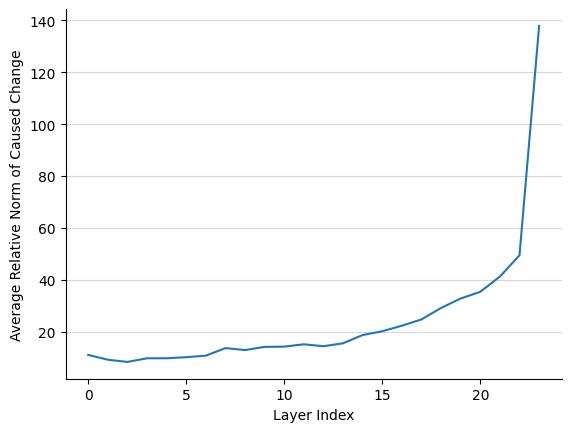

In [19]:
print(list(rel_norm_L2_means))
plt.plot(rel_norm_L2_means)
plt.xlabel('Layer Index')
plt.ylabel('Average Relative Norm of Caused Change')
plt.grid(axis='y', alpha=0.5)
sns.despine()

---
# Compute weighted relative norm of MLP output

In [13]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.grad_imp = torch.Tensor(importance.iloc[:, i])

In [29]:
# weighting individual changes by neuron importance
# using relative norms (ratio ||f(x)|| / ||x|| instead of ||f(x)||)

@torch.no_grad()
def compute_mlp_w_rel_norm(model):
    def hook_mlp(module, inps, outs):
        # take square value of output and weight using grad_imp
        w_outs_abs = outs.square().detach().cpu() * module.grad_imp
        inps_abs = inps[0].abs().detach().cpu()
        
        w_rel_L1 = rel_L1_norm(inps_abs, w_outs_abs)
        w_rel_L2 = rel_L2_norm(inps_abs, w_outs_abs)
        w_rel_max = rel_max_norm(inps_abs, w_outs_abs)
        
        module.w_rel_norms_L1.extend(
            w_rel_L1.flatten().float().tolist())
        module.w_rel_norms_L2.extend(
            w_rel_L2.flatten().float().tolist())
        module.w_rel_norms_max.extend(
            w_rel_max.flatten().float().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.w_rel_norms_L1 = []
        layer.mlp.w_rel_norms_L2 = []
        layer.mlp.w_rel_norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_w_rel_norm(model)

In [30]:
# collect norms from layers
w_rel_norms_L1 = pd.DataFrame({
    i: layer.mlp.w_rel_norms_L1
    for i, layer in enumerate(model.model.layers)})
w_rel_norms_L2 = pd.DataFrame({
    i: layer.mlp.w_rel_norms_L2
    for i, layer in enumerate(model.model.layers)})
w_rel_norms_max = pd.DataFrame({
    i: layer.mlp.w_rel_norms_max
    for i, layer in enumerate(model.model.layers)})

w_rel_norm_L2_means = w_rel_norms_L2.mean()

w_rel_norms_L1.to_csv('w_rel_norms_L1.csv')
w_rel_norms_L2.to_csv('w_rel_norms_L2.csv')
w_rel_norms_max.to_csv('w_rel_norms_max.csv')

---
# Layer-Skipping Strategies

In [13]:
class SkipMLP(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x, device=DEV)

## Removing layers from the least significant

### Based on the average L2 norm of MLP output 

In [25]:
results = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

t0 = time.time()
ppl = eval_ppl(model, wiki_testloader, device=DEV)
t = time.time() - t0
results.loc[num_skipped] = [ppl, t, 0]
print(f'ppl {ppl}, time {t}\n')

for i in norm_L2_means.argsort():
    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results.to_csv('results.csv')
results

ppl 7.260688781738281, time 118.73498272895813

skipped MLPs 1 [0]
ppl 205480.921875, time 111.60577440261841



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,205480.921875,111.605774,14.517113


#### Keeping the first two layers

In [19]:
# keeping the first two layers
results2 = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0
results2.loc[0] = results.iloc[0]

for i in norm_L2_means.argsort()[2:]:
    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results2.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results2.to_csv('results2.csv')
results2

skipped MLPs 1 [2]
ppl 8.404780387878418, time 9.363569498062134

skipped MLPs 2 [2, 3]
ppl 15.28995418548584, time 9.237032175064087

skipped MLPs 3 [2, 3, 4]
ppl 75.13276672363281, time 9.0710289478302

skipped MLPs 4 [2, 3, 4, 5]
ppl 227.93359375, time 8.945168495178223

skipped MLPs 5 [2, 3, 4, 5, 6]
ppl 5963.49951171875, time 8.76164984703064

skipped MLPs 6 [2, 3, 4, 5, 6, 8]
ppl 16087.7119140625, time 8.60029911994934



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,8.404780,9.363569,19.324569
2,15.289954,9.237032,25.971058
3,75.132767,9.071029,28.535166
4,227.933594,8.945168,31.641284
5,5963.499512,8.761650,36.316221
6,16087.711914,8.600299,50.885283


### Based on the average weighted relative L2 norm of MLP output 

In [34]:
w_rel_norm_L2_means = w_rel_norms_L2.mean()

results_w_rel_L2 = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

t0 = time.time()
ppl = eval_ppl(model, wiki_testloader, device=DEV)
t = time.time() - t0
results_w_rel_L2.loc[num_skipped] = [ppl, t, 0]
print(f'ppl {ppl}, time {t}\n')

for i in w_rel_norm_L2_means.argsort():
    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_w_rel_L2.loc[num_skipped] = [ppl, t, w_rel_norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_w_rel_L2.to_csv('results_w_rel_L2.csv')
results_w_rel_L2

ppl 7.260688781738281, time 9.717256546020508

skipped MLPs 1 [5]
ppl 7.853992462158203, time 9.074483394622803

skipped MLPs 2 [5, 16]
ppl 8.939290046691895, time 8.933717727661133

skipped MLPs 3 [5, 16, 12]
ppl 9.65140151977539, time 8.80275845527649

skipped MLPs 4 [5, 16, 12, 6]
ppl 50.559051513671875, time 8.655899286270142

skipped MLPs 5 [5, 16, 12, 6, 13]
ppl 80.89555358886719, time 8.52590036392212

skipped MLPs 6 [5, 16, 12, 6, 13, 15]
ppl 161.22007751464844, time 8.36916208267212

skipped MLPs 7 [5, 16, 12, 6, 13, 15, 8]
ppl 372.9532165527344, time 8.218833923339844

skipped MLPs 8 [5, 16, 12, 6, 13, 15, 8, 4]
ppl 1130.4888916015625, time 8.087848663330078

skipped MLPs 9 [5, 16, 12, 6, 13, 15, 8, 4, 18]
ppl 1747.980712890625, time 7.934675455093384

skipped MLPs 10 [5, 16, 12, 6, 13, 15, 8, 4, 18, 10]
ppl 3415.16015625, time 7.78162407875061

skipped MLPs 11 [5, 16, 12, 6, 13, 15, 8, 4, 18, 10, 17]
ppl 4751.50244140625, time 7.6301515102386475

skipped MLPs 12 [5, 16, 12, 

,perplexity,inference_time,layer_diff
0,7.260689,9.717257,0.000000
1,7.853992,9.074483,0.000140
2,8.939290,8.933718,0.000144
3,9.651402,8.802758,0.000145
4,50.559052,8.655899,0.000147
5,80.895554,8.525900,0.000147
6,161.220078,8.369162,0.000167
7,372.953217,8.218834,0.000199
8,1130.488892,8.087849,0.000216
9,1747.980713,7.934675,0.000224


## Shallow first

In [ ]:
# nespustam lebo pri wikitext to je cca to iste poradie ako ^

In [ ]:
results_shallow = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_shallow.loc[0] = results.iloc[0]

# when starting from layer 0 => very high perplexity
for i in range(1, 30):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_shallow.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_shallow.to_csv('results_shallow.csv')
results_shallow

## Deep first

In [27]:
results_deep = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_deep.loc[0] = results.iloc[0]

for i in range(len(model.model.layers)-1, -1, -1):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_deep.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_deep.to_csv('results_deep.csv')
results_deep

skipped MLPs 1 [23]
ppl 19.54170036315918, time 40.198424100875854

skipped MLPs 2 [23, 22]
ppl 46.562435150146484, time 48.91805577278137

skipped MLPs 3 [23, 22, 21]
ppl 79.74234771728516, time 58.21906661987305

skipped MLPs 4 [23, 22, 21, 20]
ppl 199.9649200439453, time 53.288578271865845

skipped MLPs 5 [23, 22, 21, 20, 19]
ppl 415.5325927734375, time 34.325395822525024

skipped MLPs 6 [23, 22, 21, 20, 19, 18]
ppl 2120.968994140625, time 30.37784457206726

skipped MLPs 7 [23, 22, 21, 20, 19, 18, 17]
ppl 13959.5556640625, time 44.571250438690186



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,19.541700,40.198424,1903.564499
2,46.562435,48.918056,417.581928
3,79.742348,58.219067,306.334278
4,199.964920,53.288578,257.757368
5,415.532593,34.325396,232.757663
6,2120.968994,30.377845,192.875219
7,13959.555664,44.571250,144.474050


In [26]:
# keeping the last layer
results_deep2 = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_deep2.loc[0] = results.iloc[0]

for i in range(len(model.model.layers)-2, -1, -1):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_deep2.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_deep2.to_csv('results_deep2.csv')
results_deep2

skipped MLPs 1 [22]
ppl 9.219160079956055, time 111.68365907669067

skipped MLPs 2 [22, 21]
ppl 11.802694320678711, time 106.78074336051941

skipped MLPs 3 [22, 21, 20]
ppl 18.034997940063477, time 102.74846959114075

skipped MLPs 4 [22, 21, 20, 19]
ppl 26.99382972717285, time 55.90725564956665

skipped MLPs 5 [22, 21, 20, 19, 18]
ppl 55.10776901245117, time 51.374364614486694

skipped MLPs 6 [22, 21, 20, 19, 18, 17]
ppl 103.0418472290039, time 47.62266397476196

skipped MLPs 7 [22, 21, 20, 19, 18, 17, 16]
ppl 206.48678588867188, time 44.55328726768494

skipped MLPs 8 [22, 21, 20, 19, 18, 17, 16, 15]
ppl 462.5823669433594, time 43.64814257621765

skipped MLPs 9 [22, 21, 20, 19, 18, 17, 16, 15, 14]
ppl 1071.9088134765625, time 57.1745548248291

skipped MLPs 10 [22, 21, 20, 19, 18, 17, 16, 15, 14, 13]
ppl 2504.923828125, time 38.10883116722107

skipped MLPs 11 [22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12]
ppl 4524.35205078125, time 36.764837980270386

skipped MLPs 12 [22, 21, 20, 19, 18, 

,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,9.219160,111.683659,417.581928
2,11.802694,106.780743,306.334278
3,18.034998,102.748470,257.757368
4,26.993830,55.907256,232.757663
5,55.107769,51.374365,192.875219
6,103.041847,47.622664,144.474050
7,206.486786,44.553287,115.672240
8,462.582367,43.648143,92.671017
9,1071.908813,57.174555,80.693551


## Removing layers in random order

In [18]:
results_rand = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

indices = list(range(1, len(model.model.layers)))
random.shuffle(indices)
print(indices)
skipped = {}
num_skipped = 0

results_rand.loc[0] = results.iloc[0]

for i in indices:
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_rand.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_rand.to_csv('results_rand.csv')
results_rand

[17, 13, 6, 20, 9, 5, 7, 3, 19, 15, 10, 4, 2, 14, 12, 18, 8, 11, 16, 1, 21, 22, 23]
skipped MLPs 1 [17]
ppl 8.556988716125488, time 9.251898288726807

skipped MLPs 2 [17, 13]
ppl 9.421856880187988, time 9.03812861442566

skipped MLPs 3 [17, 13, 6]
ppl 25.965190887451172, time 8.906183242797852

skipped MLPs 4 [17, 13, 6, 20]
ppl 34.7193603515625, time 8.765807390213013

skipped MLPs 5 [17, 13, 6, 20, 9]
ppl 51.2685661315918, time 8.64929723739624

skipped MLPs 6 [17, 13, 6, 20, 9, 5]
ppl 75.61019134521484, time 8.482697010040283

skipped MLPs 7 [17, 13, 6, 20, 9, 5, 7]
ppl 5157.16552734375, time 8.311204671859741

skipped MLPs 8 [17, 13, 6, 20, 9, 5, 7, 3]
ppl 23367.982421875, time 8.160892486572266



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,8.556989,9.251898,144.474050
2,9.421857,9.038129,66.324220
3,25.965191,8.906183,36.316221
4,34.719360,8.765807,257.757368
5,51.268566,8.649297,57.390542
6,75.610191,8.482697,31.641284
7,5157.165527,8.311205,52.295473
8,23367.982422,8.160892,25.971058


# Overall Layer Importance

## Removing a single layer

In [19]:
results_1_layer = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}

for i in range(len(model.model.layers)):
    gc.collect()
    torch.cuda.empty_cache()

    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLP {i}')

    t0 = time.time()
    ppl = eval_ppl(model, testloader, device=DEV)
    t = time.time() - t0
    results_1_layer.loc[i] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    # repair
    model.model.layers[i].mlp = copy.deepcopy(skipped[i])

results_1_layer.to_csv('results_1_layer.csv')
results_1_layer

skipped MLP 0
ppl 459233.21875, time 16.94073486328125

skipped MLP 1
ppl 118078.3671875, time 16.943869590759277

skipped MLP 2
ppl 13.193938255310059, time 17.21517062187195

skipped MLP 3
ppl 13.404836654663086, time 17.27972388267517

skipped MLP 4
ppl 12.740373611450195, time 17.317625045776367

skipped MLP 5
ppl 12.518013954162598, time 17.296815872192383

skipped MLP 6
ppl 32.56784439086914, time 17.24849843978882

skipped MLP 7
ppl 310.1141357421875, time 17.228058338165283

skipped MLP 8
ppl 12.719592094421387, time 17.24039125442505

skipped MLP 9
ppl 12.703290939331055, time 17.228145837783813

skipped MLP 10
ppl 12.544315338134766, time 17.208868265151978

skipped MLP 11
ppl 12.491768836975098, time 17.23180603981018

skipped MLP 12
ppl 12.387331008911133, time 36.73731803894043

skipped MLP 13
ppl 12.406124114990234, time 38.081098794937134

skipped MLP 14
ppl 12.46267032623291, time 38.24889636039734

skipped MLP 15
ppl 12.670743942260742, time 38.22993326187134

skipped 

,perplexity,inference_time,layer_diff
0,459233.218750,16.940735,14.517113
1,118078.367188,16.943870,18.388416
2,13.193938,17.215171,19.324569
3,13.404837,17.279724,25.971058
4,12.740374,17.317625,28.535166
5,12.518014,17.296816,31.641284
6,32.567844,17.248498,36.316221
7,310.114136,17.228058,52.295473
8,12.719592,17.240391,50.885283
9,12.703291,17.228146,57.390542


## Removing layers based on overall importance

In [23]:
results_overall_imp = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

indices = results_1_layer.perplexity.argsort()
print(indices.to_list())
skipped = {}
num_skipped = 0

results_overall_imp.loc[0] = results.iloc[0]

for i in indices:
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_overall_imp.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_overall_imp.to_csv('results_overall_imp.csv')
results_overall_imp

[12, 13, 14, 11, 5, 10, 15, 9, 8, 4, 16, 2, 17, 21, 3, 20, 18, 19, 22, 23, 6, 7, 1, 0]
skipped MLPs 1 [12]
ppl 7.6639604568481445, time 21.13063669204712

skipped MLPs 2 [12, 13]
ppl 8.323542594909668, time 20.771050453186035

skipped MLPs 3 [12, 13, 14]
ppl 9.485733985900879, time 20.39441156387329

skipped MLPs 4 [12, 13, 14, 11]
ppl 11.678743362426758, time 13.672844409942627

skipped MLPs 5 [12, 13, 14, 11, 5]
ppl 13.189115524291992, time 8.812801599502563

skipped MLPs 6 [12, 13, 14, 11, 5, 10]
ppl 50.23979568481445, time 8.636222839355469

skipped MLPs 7 [12, 13, 14, 11, 5, 10, 15]
ppl 102.911376953125, time 8.468592405319214

skipped MLPs 8 [12, 13, 14, 11, 5, 10, 15, 9]
ppl 396.33648681640625, time 8.289565563201904

skipped MLPs 9 [12, 13, 14, 11, 5, 10, 15, 9, 8]
ppl 47947.984375, time 8.148386716842651



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,7.663960,21.130637,59.953614
2,8.323543,20.771050,66.324220
3,9.485734,20.394412,80.693551
4,11.678743,13.672844,61.975333
5,13.189116,8.812802,31.641284
6,50.239796,8.636223,58.834559
7,102.911377,8.468592,92.671017
8,396.336487,8.289566,57.390542
9,47947.984375,8.148387,50.885283


# Results

In [5]:
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results.loc[:, 'log_perplexity'] = [np.log(x) for x in results.perplexity]
results2.loc[:, 'log_perplexity'] = [np.log(x) for x in results2.perplexity]
results_deep.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep.perplexity]
results_deep2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep2.perplexity]
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results_1_layer.loc[:, 'log_perplexity'] = [np.log(x) for x in results_1_layer.perplexity]
results_overall_imp.loc[:, 'log_perplexity'] = [np.log(x) for x in results_overall_imp.perplexity]
results_w_rel_L2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_w_rel_L2.perplexity]
# results_threshold_L1.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L1.perplexity]
# results_threshold_L2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L2.perplexity]
# results_threshold_max.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_max.perplexity]

### Layer Importance

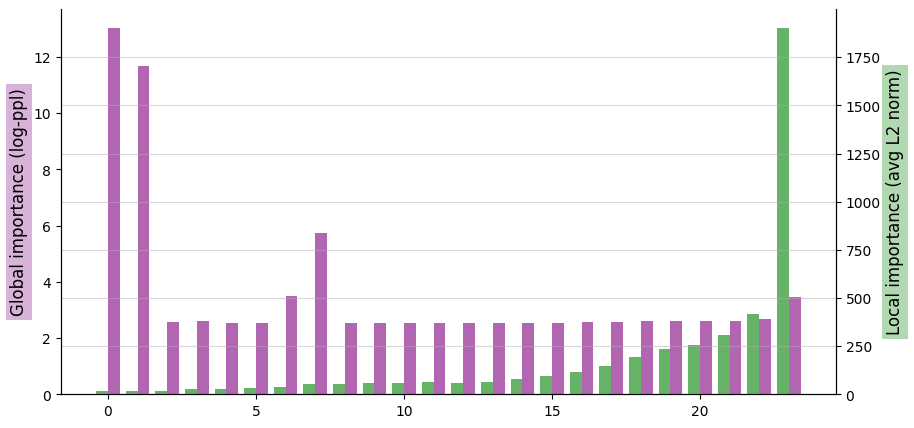

In [17]:
fig, ax1 = plt.subplots(figsize=(10, 5))

layer_indices = np.arange(len(norms_L2.mean()))  # X-axis positions
width = 0.4  # Width of bars

# Primary y-axis for norms (Bar plot)
ax1.bar(layer_indices + width/2, results_1_layer.log_perplexity, width=width,
        label='Log-Perplexity', color='purple', alpha=0.6)
ax1.set_ylabel('Global importance (log-ppl)', fontsize=12,
               bbox=dict(facecolor='purple', alpha=0.3, edgecolor='none', pad=3))
# ax1.set_ylabel('Log-Perplexity of Pruned Model', fontsize=12,
#                bbox=dict(facecolor='purple', alpha=0.3, edgecolor='none', pad=3))

# Secondary y-axis for perplexity (Bar plot)
ax2 = ax1.twinx()
ax2.bar(layer_indices - width/2, norms_L2.mean(), width=width, label='Norm', color='green', alpha=0.6)
ax2.set_xlabel('Layer Index')
ax2.set_ylabel('Local importance (avg L2 norm)', fontsize=12,
               bbox=dict(facecolor='green', alpha=0.3, edgecolor='none', pad=3))
# ax2.set_ylabel('Average Norm of Change', fontsize=12,
#                bbox=dict(facecolor='green', alpha=0.3, edgecolor='none', pad=3))
ax2.set_xticks(range(0, len(norms_L2.mean()), 5))
ax2.grid(axis='y', alpha=0.5)

# plt.title("Layer Importance", fontsize=14)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center')

sns.despine(right=False)  # Keep right spine for secondary axis
plt.show()


## Multiple layers - different strategies

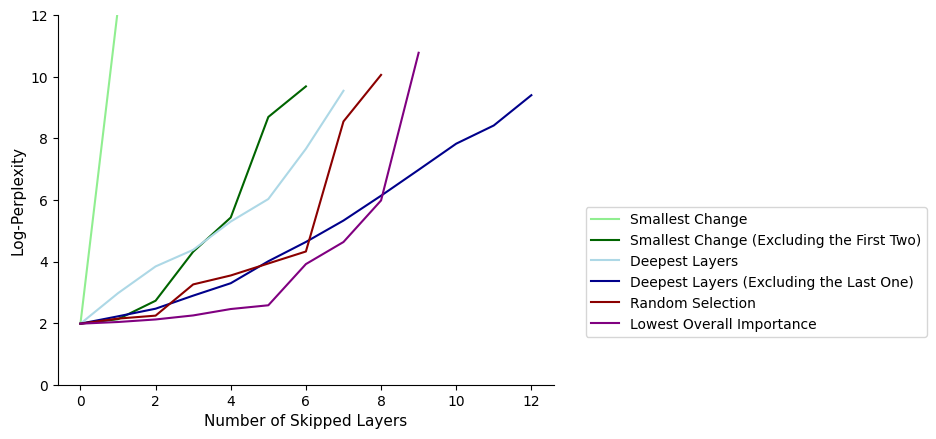

In [26]:
plt.plot(results.log_perplexity, label='Smallest Change', color='lightgreen')
plt.plot(results2.log_perplexity, label='Smallest Change (Excluding the First Two)', color='darkgreen')
plt.plot(results_deep.log_perplexity, label='Deepest Layers', color='lightblue')
plt.plot(results_deep2.log_perplexity, label='Deepest Layers (Excluding the Last One)', color='darkblue')
# plt.plot(results_shallow.log_perplexity, label='Shallow Layers')
plt.plot(results_rand.log_perplexity, label='Random Selection', color='darkred')
plt.plot(results_overall_imp.log_perplexity, label='Lowest Overall Importance', color='purple')

plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Log-Perplexity', fontsize=11)
plt.ylim((0, 12))
# plt.legend(loc='lower right')
plt.legend(bbox_to_anchor=(1.05, 0.5))
# plt.title('Layer-Skipping Strategies')
sns.despine()

# Deleting small changes

In [28]:
gc.collect()
torch.cuda.empty_cache()

In [16]:
@torch.no_grad()
def delete_small_changes(model, layers_to_keep=tuple()):
    def hook_l1_threshold(module, inps, outs):
        token_norms = outs.abs().sum(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L1
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_l2_threshold(module, inps, outs):
        token_norms = outs.norm(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L2
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_max_threshold(module, inps, outs):
        token_norms = outs.abs().max(dim=2, keepdim=True).values
        mask = token_norms >= module.threshold_max
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    norm_types = ('L1', 'L2', 'max')

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    for q in range(10, 71, 5):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_L1 = mlp.norms_L1.quantile(q)
            mlp.threshold_L2 = mlp.norms_L2.quantile(q)
            mlp.threshold_max = mlp.norms_max.quantile(q)

        for norm_type, hook in zip(norm_types, (hook_l1_threshold, hook_l2_threshold, hook_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache

    return results_threshold

results_threshold = delete_small_changes(model)
results_threshold = results_threshold.unstack(level=0)
results_threshold.to_csv('results/results_threshold.csv')

percentile 10
L1 norm	--> deleted ratio 14.827144, ppl 19.774139
L2 norm	--> deleted ratio 7.936289, ppl 12.265088
max norm	--> deleted ratio 9.436214, ppl 14.614442

percentile 15
L1 norm	--> deleted ratio 34.209875, ppl 160.880035
L2 norm	--> deleted ratio 14.880962, ppl 32.437248
max norm	--> deleted ratio 12.694900, ppl 24.765697

percentile 20
L1 norm	--> deleted ratio 43.221194, ppl 1270.238281
L2 norm	--> deleted ratio 22.553315, ppl 84.064819
max norm	--> deleted ratio 15.109775, ppl 49.273273

percentile 25
L1 norm	--> deleted ratio 47.823396, ppl 8185.631836
L2 norm	--> deleted ratio 32.078057, ppl 320.624420
max norm	--> deleted ratio 17.329104, ppl 135.074707

percentile 30
L1 norm	--> deleted ratio 51.323707, ppl 62036.171875
L2 norm	--> deleted ratio 39.930574, ppl 929.326172
max norm	--> deleted ratio 20.753355, ppl 389.697815

percentile 35
L1 norm	--> deleted ratio 53.781939, ppl 285643.562500
L2 norm	--> deleted ratio 44.331057, ppl 6101.049805
max norm	--> deleted ra

## Initial results

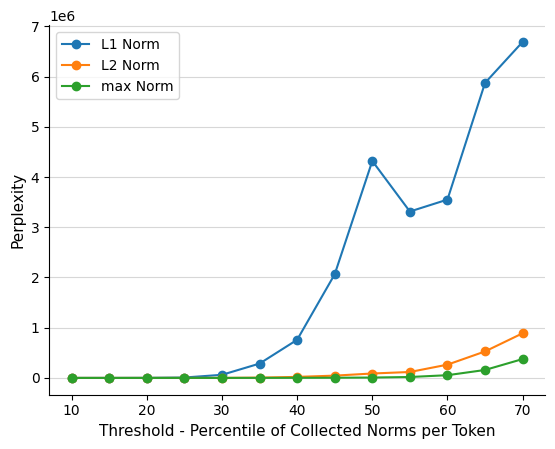

In [17]:
# podla akeho percetilu bol nastaveny threshold
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'L1')], label='L1 Norm', marker='o')
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'L2')], label='L2 Norm', marker='o')
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'max')], label='max Norm', marker='o')
plt.xlabel('Threshold - Percentile of Collected Norms per Token', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.5)
sns.despine()

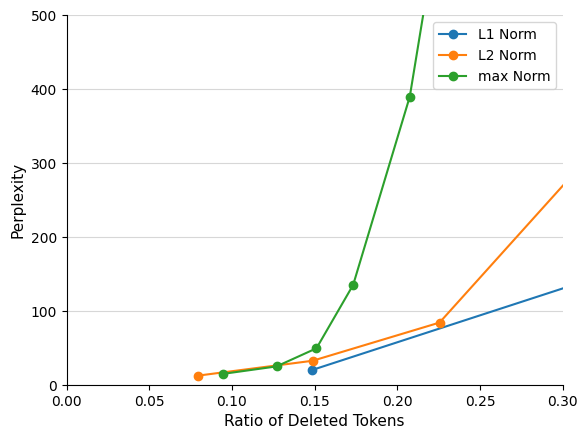

In [18]:
# kolko hodnot bolo realne vynulovanych
plt.plot(results_threshold.loc[:, ('ratio_del', 'L1')], results_threshold.loc[:, ('perplexity', 'L1')], label='L1 Norm', marker='o')
plt.plot(results_threshold.loc[:, ('ratio_del', 'L2')], results_threshold.loc[:, ('perplexity', 'L2')], label='L2 Norm', marker='o')
plt.plot(results_threshold.loc[:, ('ratio_del', 'max')], results_threshold.loc[:, ('perplexity', 'max')], label='max Norm', marker='o')
plt.xlim((0, 0.3))
plt.ylim((0, 500))
plt.xlabel('Ratio of Deleted Tokens', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.5)
sns.despine()

## Keeping some layers unchanged

In [ ]:
# using l2 norm, quantile 0.3
@torch.no_grad()
def special_layers_combinations(model):
    def l2_threshold(module, inps, outs):
        token_norms = outs.norm(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L2
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask
        
    q = 0.3
    last = len(model.model.layers) - 1
    imp_order = results_1_layer.perplexity.argsort()[::-1]
    layer_combinations = [
        (), (0,), (last,),
         (0, 1), (0, 1, 2), (0, 1, 2, 3),
        (0, last), (0, last-1, last), (0, last-2, last-1, last),
        (0, 1, last), (0, 1, last-1, last), (0, 1, 2, last)
    ] + [
        tuple(results_1_layer.perplexity.argsort()[::-1])[:i] for i in range(2, 5)
    ]

    use_cache = model.config.use_cache
    model.config.use_cache = False

    gc.collect()
    torch.cuda.empty_cache()

    results_thr_keeping_layers = pd.DataFrame(columns=['perplexity', 'ratio_del'])

    for ls in layer_combinations:
        print('layers kept unchanged:', ls)
        hooks = []
        ratio_over_thr = []
        for i, layer in enumerate(model.model.layers):
            if i in ls:
                ratio_over_thr.append(1)
                continue

            mlp = layer.mlp
            mlp.threshold_L2 = mlp.norms_L2.quantile(q)
            h = mlp.register_forward_hook(l2_threshold)
            hooks.append(h)

        ppl = eval_ppl(model, wiki_testloader, device=DEV)
        ratio_del = 1 - np.mean(ratio_over_thr)
        print(f'deleted ratio {ratio_del*100:.2f} --> ppl {ppl:.2f}')
        results_thr_keeping_layers.loc[str(ls)] = [ppl, ratio_del]

        for h in hooks:
            h.remove()

    model.config.use_cache = use_cache

    return results_thr_keeping_layers

results_thr_keeping_layers = special_layers_combinations(model)
results_thr_keeping_layers.to_csv('results/results_thr_keeping_layers.csv')

In [35]:
results_thr_keeping_layers

,perplexity,ratio_del
(),929.326172,0.399306
"(0,)",128.345993,0.351830
"(23,)",196.864746,0.377086
"(0, 1)",100.676147,0.350486
"(0, 1, 2)",66.108734,0.328414
"(0, 1, 2, 3)",46.582100,0.318289
"(0, 23)",41.073849,0.332854
"(0, 22, 23)",32.205215,0.313359
"(0, 21, 22, 23)",26.508076,0.295481
"(0, 1, 23)",33.143436,0.332217


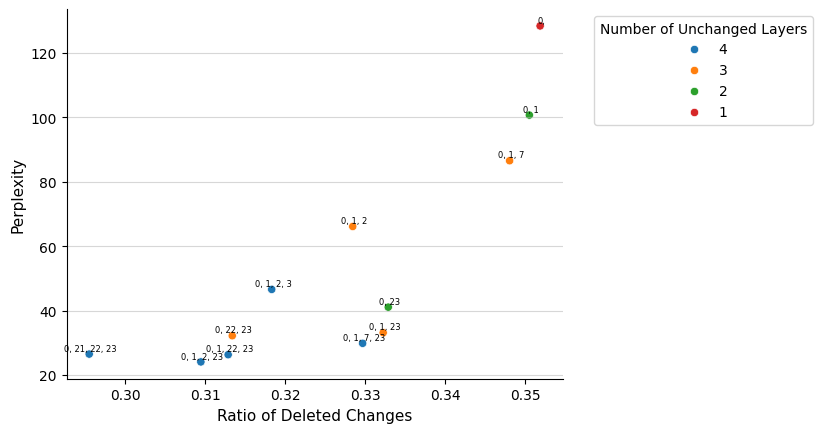

In [36]:
rtkl = results_thr_keeping_layers.sort_values(by='perplexity')[:-2]
rtkl['num_layers_untouched'] = list(map(lambda x: len(x[1:-1].split(', ')), rtkl.index))

categories = rtkl.num_layers_untouched.astype(str)
palette = sns.color_palette("tab10", n_colors=len(categories.unique()))
sns.scatterplot(x=rtkl.ratio_del, y=rtkl.perplexity, hue=categories, palette=palette)

for i, txt in enumerate(rtkl.index):
    plt.text(rtkl.ratio_del.iloc[i]+0.0002, rtkl.perplexity.iloc[i]+0.4, txt[1:-1], fontsize=6, ha='center', va='bottom')

plt.xlabel('Ratio of Deleted Changes', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.grid(axis='y', alpha=0.5)
plt.legend(title="Number of Unchanged Layers", bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.show()

In [38]:
# layer combinations with best ratios
(results_thr_keeping_layers.perplexity/results_thr_keeping_layers.ratio_del).sort_values().iloc[:5]

(0, 1, 2, 23)      77.802089
(0, 1, 22, 23)     84.126124
(0, 21, 22, 23)    89.711697
(0, 1, 7, 23)      90.543665
(0, 1, 23)         99.764275
dtype: float64

## Different thresholds and norm types

In [19]:
layers_to_keep = (0, 1, 23)

### Absolute norm

In [20]:
results_threshold_except = delete_small_changes(model, layers_to_keep)
results_threshold_except = results_threshold_except.unstack(level=0)
results_threshold_except.to_csv('results/results_threshold_except.csv')

percentile 10
L1 norm	--> deleted ratio 10.558393, ppl 14.194742
L2 norm	--> deleted ratio 7.451782, ppl 8.982807
max norm	--> deleted ratio 9.945084, ppl 9.072396

percentile 15
L1 norm	--> deleted ratio 18.840786, ppl 20.444965
L2 norm	--> deleted ratio 14.407943, ppl 11.302709
max norm	--> deleted ratio 13.962246, ppl 10.640355

percentile 20
L1 norm	--> deleted ratio 26.313023, ppl 39.843781
L2 norm	--> deleted ratio 20.927781, ppl 15.122994
max norm	--> deleted ratio 17.561912, ppl 12.848275

percentile 25
L1 norm	--> deleted ratio 32.466665, ppl 55.857525
L2 norm	--> deleted ratio 27.279992, ppl 21.534990
max norm	--> deleted ratio 21.132828, ppl 16.105143

percentile 30
L1 norm	--> deleted ratio 38.359735, ppl 96.594688
L2 norm	--> deleted ratio 33.221749, ppl 33.143436
max norm	--> deleted ratio 24.857835, ppl 21.680990

percentile 35
L1 norm	--> deleted ratio 43.349625, ppl 159.257706
L2 norm	--> deleted ratio 38.508176, ppl 52.517620
max norm	--> deleted ratio 28.968365, ppl 

### Relative norm

In [40]:
def get_rel_L1_threshold(module):
    return module.threshold_rel_L1

def get_rel_L2_threshold(module):
    return module.threshold_rel_L2

def get_rel_max_threshold(module):
    return module.threshold_rel_max

def get_w_rel_L1_threshold(module):
    return module.threshold_w_rel_L1

def get_w_rel_L2_threshold(module):
    return module.threshold_w_rel_L2

def get_w_rel_max_threshold(module):
    return module.threshold_w_rel_max

In [24]:
@torch.no_grad()
def delete_small_rel_changes(model):
    def hook_threshold(module, inps, outs):
        token_norms = norm_function(inps[0].abs(), outs.abs())
        mask = token_norms >= get_threshold(module)
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold_rel = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    norm_types = ('L1', 'L2', 'max')
    for q in range(10, 71, 5):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_rel_L1 = mlp.rel_thresholds_L1[q]
            mlp.threshold_rel_L2 = mlp.rel_thresholds_L2[q]
            mlp.threshold_rel_max = mlp.rel_thresholds_max[q]

        for norm_type, norm_function, get_threshold in zip(
                norm_types,
                (rel_L1_norm, rel_L2_norm, rel_max_norm),
                (get_rel_L1_threshold, get_rel_L2_threshold, get_rel_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook_threshold)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold_rel.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache
    return results_threshold_rel

results_threshold_rel_except = delete_small_rel_changes(model)
results_threshold_rel_except = results_threshold_rel_except.unstack(level=0)
results_threshold_rel_except.to_csv('results/results_threshold_rel_except.csv')

percentile 10
L1 norm		--> deleted ratio 8.472634, ppl 7.972623
L2 norm		--> deleted ratio 8.211592, ppl 7.920609
max norm		--> deleted ratio 9.524458, ppl 8.971434

percentile 15
L1 norm		--> deleted ratio 14.784937, ppl 9.273826
L2 norm		--> deleted ratio 13.575565, ppl 8.894104
max norm		--> deleted ratio 13.177756, ppl 10.446676

percentile 20
L1 norm		--> deleted ratio 21.758939, ppl 12.126037
L2 norm		--> deleted ratio 19.054581, ppl 10.678616
max norm		--> deleted ratio 16.669969, ppl 12.474029

percentile 25
L1 norm		--> deleted ratio 29.462672, ppl 18.576084
L2 norm		--> deleted ratio 24.505193, ppl 13.775457
max norm		--> deleted ratio 20.020595, ppl 15.413131

percentile 30
L1 norm		--> deleted ratio 36.939228, ppl 32.519547
L2 norm		--> deleted ratio 30.001628, ppl 19.263123
max norm		--> deleted ratio 23.335008, ppl 19.916609

percentile 35
L1 norm		--> deleted ratio 43.573217, ppl 59.711651
L2 norm		--> deleted ratio 35.328228, ppl 28.493109
max norm		--> deleted ratio 26

### Weighted relative norm

In [30]:
@torch.no_grad()
def delete_small_rel_changes(model):
    def hook_threshold(module, inps, outs):
        # weighting outputs by neuron importance
        token_norms = norm_function(inps[0].abs(), outs.square() * module.grad_imp.to(DEV))
        mask = token_norms >= get_threshold(module)
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold_rel = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    norm_types = ('L1', 'L2', 'max')
    for q in range(10, 71, 5):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_w_rel_L1 = mlp.w_rel_thresholds_L1[q]
            mlp.threshold_w_rel_L2 = mlp.w_rel_thresholds_L2[q]
            mlp.threshold_w_rel_max = mlp.w_rel_thresholds_max[q]

        for norm_type, norm_function, get_threshold in zip(
                norm_types,
                (rel_L1_norm, rel_L2_norm, rel_max_norm),
                (get_w_rel_L1_threshold, get_w_rel_L2_threshold, get_w_rel_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook_threshold)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold_rel.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache
    return results_threshold_rel

results_threshold_w_rel_except = delete_small_rel_changes(model)
results_threshold_w_rel_except = results_threshold_w_rel_except.unstack(level=0)
results_threshold_w_rel_except.to_csv('results/results_threshold_w_rel_except.csv')

percentile 10
L1 norm		--> deleted ratio 9.044362, ppl 8.149634
L2 norm		--> deleted ratio 9.803670, ppl 8.388824
max norm		--> deleted ratio 10.471927, ppl 8.907259

percentile 15
L1 norm		--> deleted ratio 15.643733, ppl 9.795112
L2 norm		--> deleted ratio 14.397207, ppl 9.572249
max norm		--> deleted ratio 14.625980, ppl 10.343515

percentile 20
L1 norm		--> deleted ratio 22.397930, ppl 12.979156
L2 norm		--> deleted ratio 18.551604, ppl 11.328989
max norm		--> deleted ratio 18.374399, ppl 12.369117

percentile 25
L1 norm		--> deleted ratio 29.080717, ppl 18.964476
L2 norm		--> deleted ratio 22.456305, ppl 13.956983
max norm		--> deleted ratio 21.988447, ppl 15.206244

percentile 30
L1 norm		--> deleted ratio 35.344223, ppl 30.254000
L2 norm		--> deleted ratio 26.137711, ppl 18.057863
max norm		--> deleted ratio 25.459016, ppl 19.344646

percentile 35
L1 norm		--> deleted ratio 40.836276, ppl 49.796227
L2 norm		--> deleted ratio 29.630487, ppl 24.278997
max norm		--> deleted ratio 2

### Results

#### Results using absolute norm

In [25]:
results_threshold_except

perplexity                            ratio_del            \
norm_type           L1           L2           max        L1        L2   
threshold                                                               
10.0         14.194742     8.982807      9.072396  0.105584  0.074518   
15.0         20.444965    11.302709     10.640355  0.188408  0.144079   
20.0         39.843781    15.122994     12.848275   0.26313  0.209278   
25.0         55.857525     21.53499     16.105143  0.324667    0.2728   
30.0         96.594688    33.143436      21.68099  0.383597  0.332217   
35.0        159.257706     52.51762     31.746115  0.433496  0.385082   
40.0        265.134277    87.764954     52.097916  0.480328  0.434363   
45.0        467.689362   142.878296    108.673119  0.523167   0.47502   
50.0        706.248108   228.704926    192.507507  0.558485  0.510476   
55.0       1151.690796   364.544556    1248.96167  0.590222  0.541714   
60.0       1812.629639   568.925781   8164.916016  0.619582  0.570046   
65.0       2567.035156   881.914368  19686.128906  0.645295  0.596371   
70.0       3922.534424  1310.560059  41993.511719  0.669331  0.621495   

                     
norm_type       max  
threshold            
10.0       0.099451  
15.0       0.139622  
20.0       0.175619  
25.0       0.211328  
30.0       0.248578  
35.0       0.289684  
40.0       0.331562  
45.0       0.377919  
50.0       0.425958  
55.0       0.486155  
60.0        0.55575  
65.0       0.635076  
70.0       0.725867

#### Results using relative norm

In [26]:
results_threshold_rel_except

perplexity                          ratio_del                    
norm_type           L1          L2          max        L1        L2       max
threshold                                                                    
10.0          7.972623    7.920609     8.971434  0.084726  0.082116  0.095245
15.0          9.273826    8.894104    10.446676  0.147849  0.135756  0.131778
20.0         12.126037   10.678616    12.474029  0.217589  0.190546    0.1667
25.0         18.576084   13.775457    15.413131  0.294627  0.245052  0.200206
30.0         32.519547   19.263123    19.916609  0.369392  0.300016   0.23335
35.0         59.711651   28.493109    27.523329  0.435732  0.353282  0.265654
40.0        109.271408   45.956844    45.918053  0.493702  0.403762  0.298371
45.0        188.167282   72.575569    71.813408   0.54029   0.44461  0.331395
50.0         312.60257  121.489937   107.759163  0.581535  0.483643  0.364036
55.0        509.766602  196.947937   302.218048  0.619603   0.51493  0.403456
60.0        756.254822  317.927917   608.181519  0.651901  0.544569  0.448044
65.0       1181.245483  501.651459  1451.576538  0.682887  0.570696  0.499055
70.0       1752.414673  760.097107  3535.494873  0.707494  0.596988  0.560039

#### Results using weighted relative norm

In [31]:
results_threshold_w_rel_except

perplexity                           ratio_del                    
norm_type          L1           L2          max        L1        L2       max
threshold                                                                    
10.0         8.149634     8.388824     8.907259  0.090444  0.098037  0.104719
15.0         9.795112     9.572249    10.343515  0.156437  0.143972   0.14626
20.0        12.979156    11.328989    12.369117  0.223979  0.185516  0.183744
25.0        18.964476    13.956983    15.206244  0.290807  0.224563  0.219884
30.0           30.254    18.057863    19.344646  0.353442  0.261377   0.25459
35.0        49.796227    24.278997    25.954229  0.408363  0.296305  0.290508
40.0        81.340881    34.108982    36.079559  0.454207  0.329947  0.324903
45.0       129.982361    50.409813    52.918339  0.492774   0.36263  0.361008
50.0       206.835938    78.076256    89.637802   0.52609  0.395018  0.396635
55.0       316.053772    128.02124   147.662994  0.554718   0.43031  0.431598
60.0       469.272034   218.139587   265.358398  0.580832  0.466228  0.465652
65.0       680.483948   399.023529   708.638123  0.605316  0.501695  0.507224
70.0        953.17395  1542.587646  2926.080566  0.629202  0.548205  0.555628

### Norm type comparison

#### Absolute norm

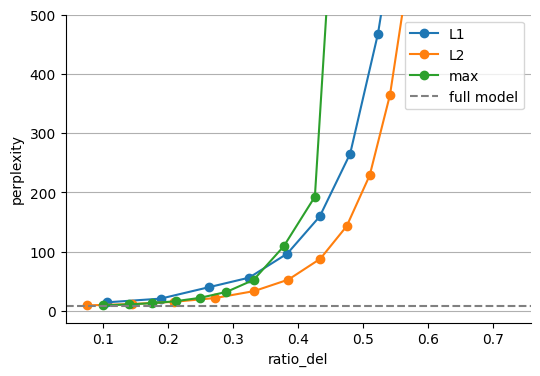

In [46]:
plt.figure(figsize=(6, 4))
norm_types = ["L1", "L2", "max"]
for norm in norm_types:
    plt.plot(results_threshold_except["ratio_del", norm], results_threshold_except["perplexity", norm], marker='o', label=norm)
plt.axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
plt.ylim(-20, 500)
plt.xlabel("ratio_del")
plt.ylabel("perplexity")
plt.legend()
plt.grid(axis='y')
sns.despine()
plt.show()

#### Relative norm

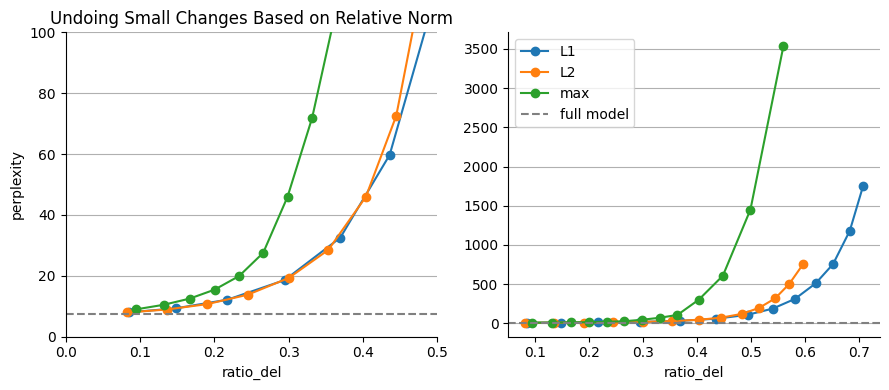

In [49]:
norm_types = ["L1", "L2", "max"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for norm in norm_types:
    axes[0].plot(results_threshold_rel_except["ratio_del", norm],
                 results_threshold_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[0].set_title("Undoing Small Changes Based on Relative Norm")
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].set_xlim(0, 0.5)
axes[0].set_ylim(0, 100)
# axes[0].legend()
axes[0].grid(axis='y')

for norm in norm_types:
    axes[1].plot(results_threshold_rel_except["ratio_del", norm],
                 results_threshold_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[1].set_xlabel("ratio_del")
axes[1].legend()
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()


#### Weighted relative norm

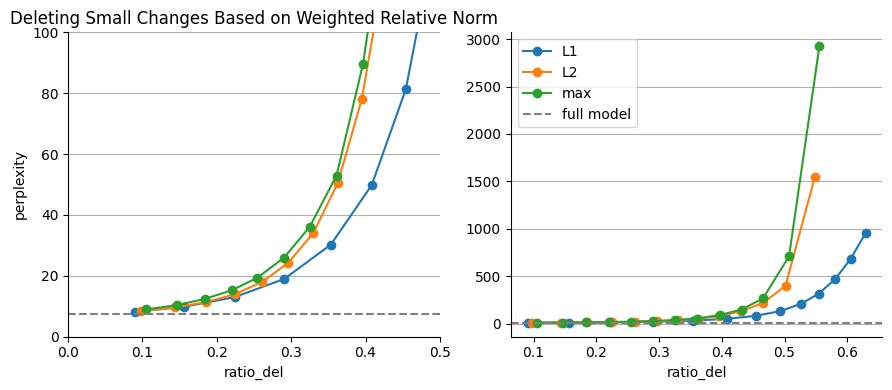

In [51]:
norm_types = ["L1", "L2", "max"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for norm in norm_types:
    axes[0].plot(results_threshold_w_rel_except["ratio_del", norm],
                 results_threshold_w_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[0].set_title("Deleting Small Changes Based on Weighted Relative Norm")
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].set_xlim(0, 0.5)
axes[0].set_ylim(0, 100)
# axes[0].legend()
axes[0].grid(axis='y')

for norm in norm_types:
    axes[1].plot(results_threshold_w_rel_except["ratio_del", norm],
                 results_threshold_w_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[1].set_xlabel("ratio_del")
axes[1].legend()
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()


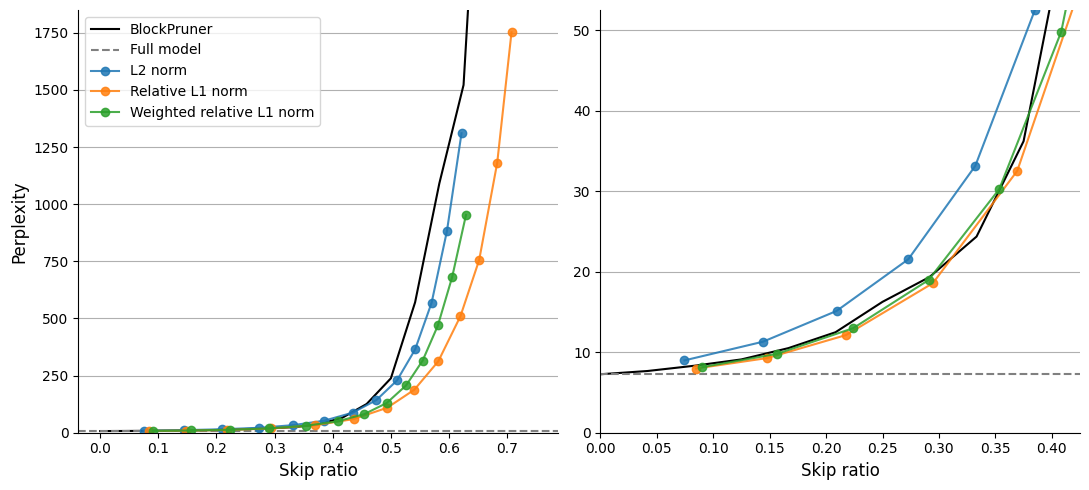

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].plot(block_pruner.loc[:, 'del_ratio'], block_pruner.loc[:, 'perplexity'], c='black', label='BlockPruner')
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')

axes[0].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', alpha=0.85, label="L2 norm")
axes[0].plot(results_threshold_rel_except["ratio_del", 'L1'], results_threshold_rel_except["perplexity", 'L1'],
             marker='o', alpha=0.85, label="Relative L1 norm")
axes[0].plot(results_threshold_w_rel_except["ratio_del", 'L1'], results_threshold_w_rel_except["perplexity", 'L1'],
             marker='o', alpha=0.85, label="Weighted relative L1 norm")

axes[0].set_ylim(0, 1850)
axes[0].set_xlabel("Skip ratio", fontsize=12)
axes[0].set_ylabel("Perplexity", fontsize=12)
axes[0].legend()
axes[0].grid(axis='y')

###

axes[1].plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

axes[1].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', alpha=0.85, label="L2 norm")
axes[1].plot(results_threshold_rel_except["ratio_del", 'L1'], results_threshold_rel_except["perplexity", 'L1'],
             marker='o', alpha=0.85, label="relative L1 norm")
axes[1].plot(results_threshold_w_rel_except["ratio_del", 'L1'], results_threshold_w_rel_except["perplexity", 'L1'],
             marker='o', alpha=0.85, label="weighted relative L1 norm")

axes[1].set_xlim(0, 0.425)
axes[1].set_ylim(0, 52.5)
axes[1].set_xlabel("Skip ratio", fontsize=12)
axes[1].grid(axis='y')


sns.despine()
plt.tight_layout()
plt.show()